# Stock Triple-Barrier Classification · 03 Features & Purged Split

# Aim, Objective, and Motivation
- **Aim:** <u>describe</u> each day with stationary, causal features that a model can learn from.
- **Objective:** build technical, volatility, volume and market features, a fractionally differenced price,
  check which features relate to the labels, and split the data by time **with purging**.
- **Motivation:** my first version fed raw (scaled) prices to the networks. Here every feature is a return, ratio or
  oscillator, computed from data up to day $t$ only, and no event's outcome may overlap the next data split.

# Outlines
1. Load prices & labels
2. Fractional differentiation
3. Feature catalogue
4. Build features
5. Which features relate to the label?
6. Purged time split
7. Save dataset
8. Summary

<!-- objective -->
## Objective

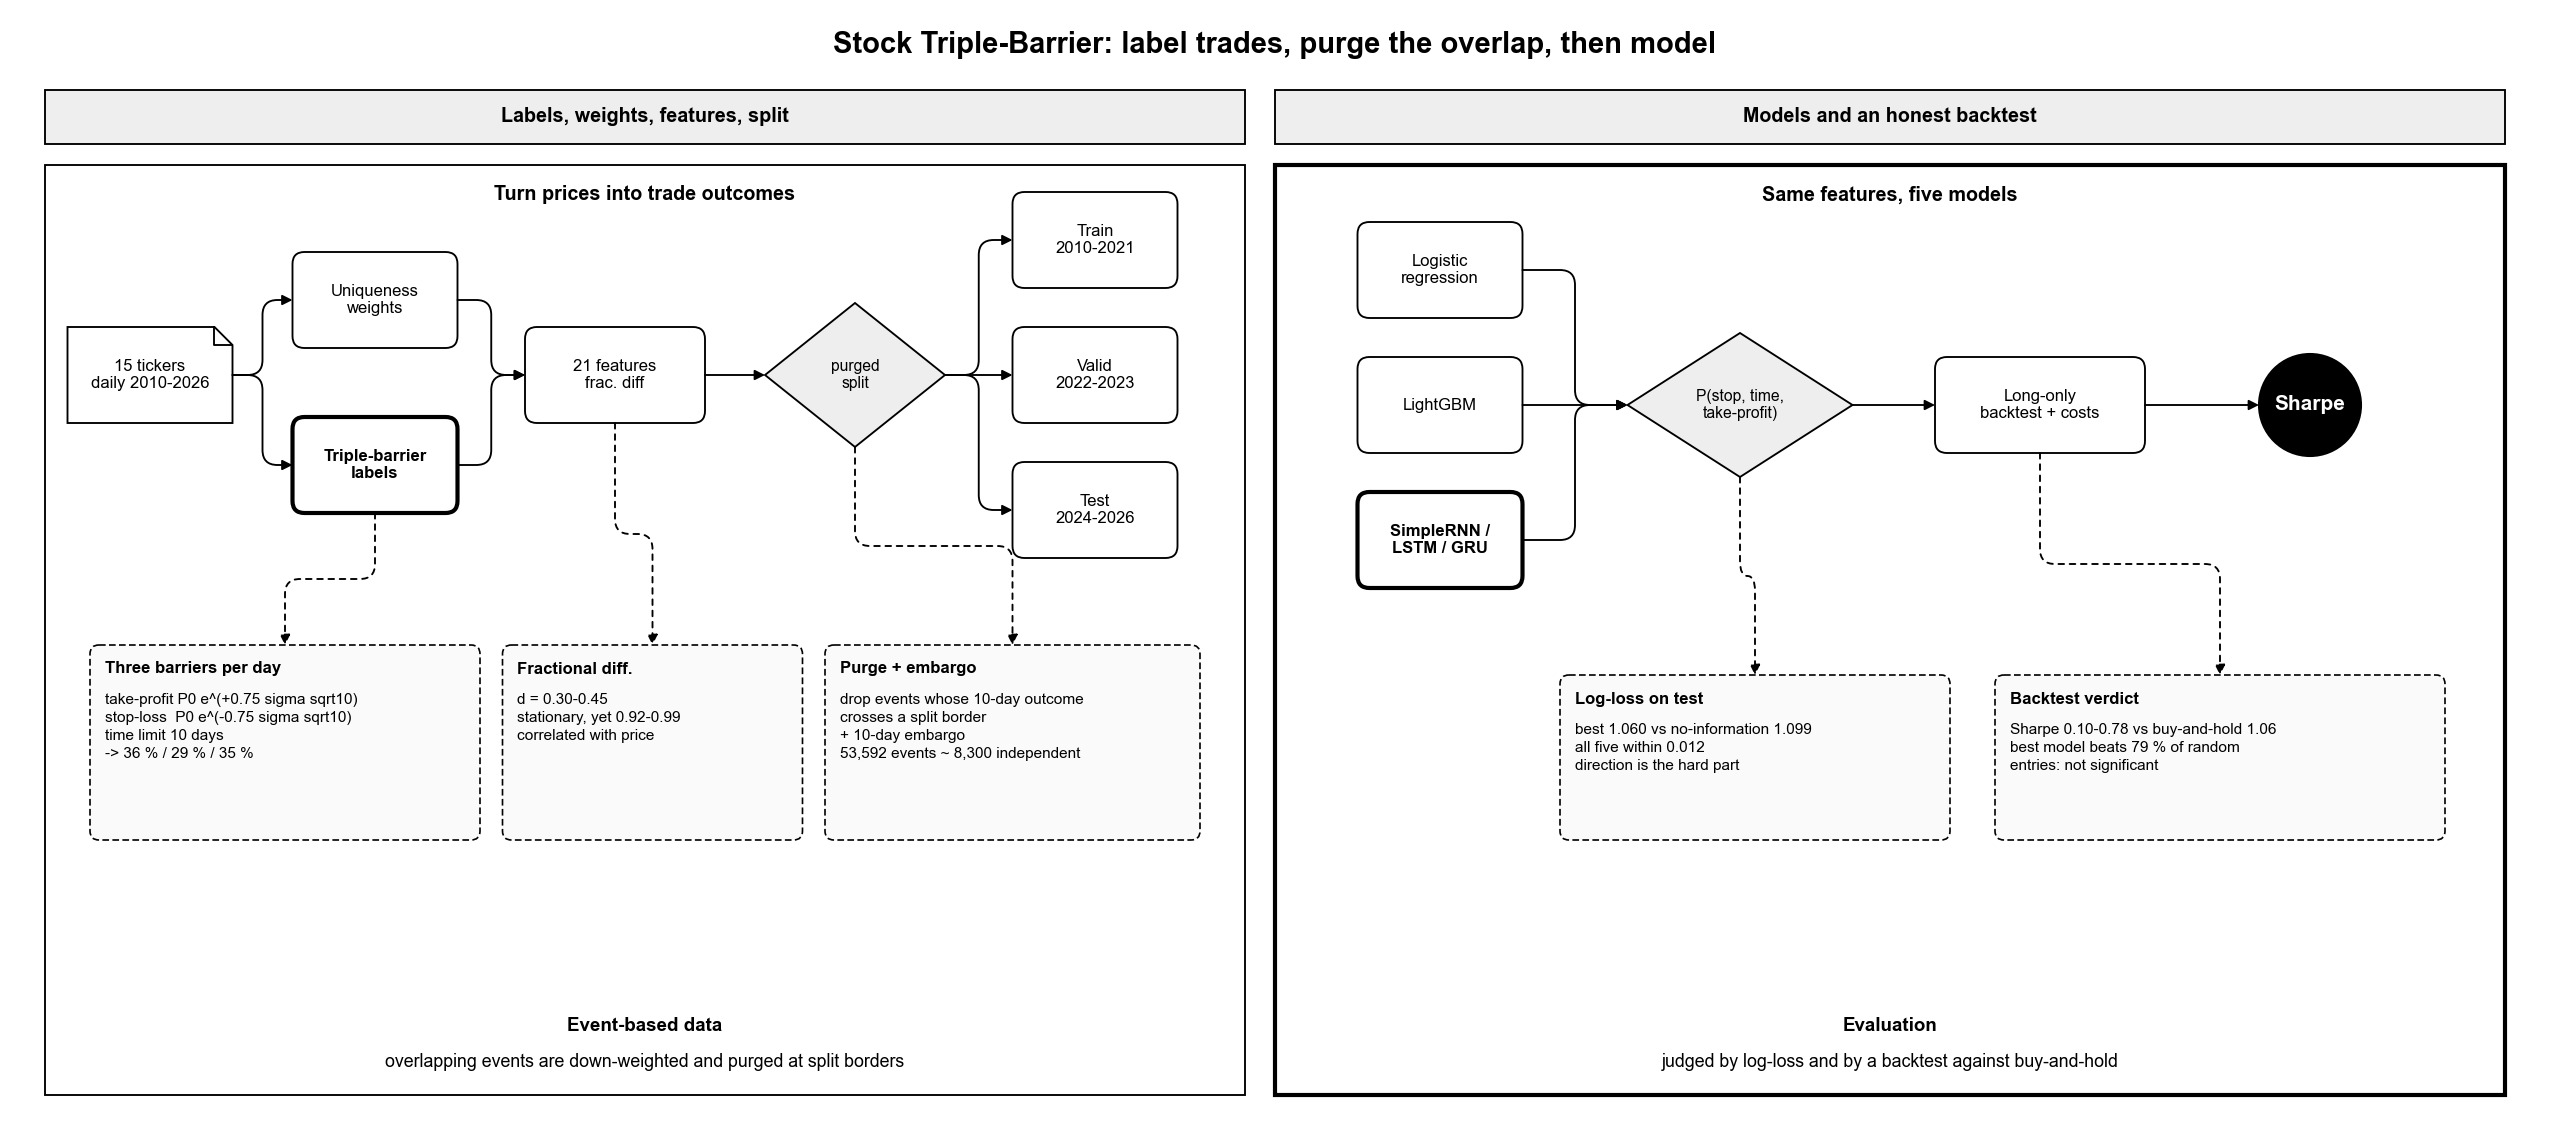

- **Problem** → most "stock prediction" notebooks predict tomorrow's price and report R² ≈ 0.99, yet copying yesterday's price scores the same: it looks smart and tells a trader nothing
- **Why this repo** → ask the question a trader actually has, *"if I buy today, do I hit my take-profit, my stop-loss, or run out of time?"*, and test it without leaking the future
- **Real-world use** → a sanity check before trusting any trading signal: label trades by outcome, purge overlapping samples, and compare against buy-and-hold and random entries

In [1]:
# ---------------------------------------------------------------- Imports
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.config import TICKERS, MARKET, VALID_START, TEST_START, CLASSES, LABEL_COLORS, PRICE_COLOR
from src.data import download_prices, load_processed, save_processed
from src.evaluate import assign_split
from src.features import frac_diff, min_d_stationary, ticker_features, FEATURES
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
EXAMPLE = "AAPL"
FFD_THRESHOLD = 1e-3                 # drop fractional-difference weights smaller than this
ADF_ALPHA = 0.05
SPLIT_COLORS = {"train": "#4b5563", "valid": "#9ca3af", "test": "#dc2626", "purged": "black"}

set_style()

# [1/8] Load prices & labels

In [2]:
prices = download_prices()
labels = load_processed("labels")
market = prices[prices.ticker == MARKET].set_index("date")

In [3]:
print(f"prices: {prices.shape} | labels: {labels.shape}")

prices: (58253, 7) | labels: (53592, 9)


# [2/8] Fractional differentiation
> **Problem:** prices are non-stationary (notebook 01), returns are stationary but throw away all memory of the price level
> (returns = first difference, $d = 1$). Fractional differentiation uses a **fractional** $d \in (0, 1)$:
>
> $\tilde{x}_t = \sum_{k=0}^{K} w_k\, x_{t-k}$, with $w_0 = 1$, $w_k = -w_{k-1}\,\frac{d - k + 1}{k}$, truncated when $|w_k| < 10^{-3}$
>
> **Question:** what is the smallest $d$ that makes each stock's log price stationary (ADF p < 0.05)?
> Chosen on the **training period only**, so the choice does not peek at the future.

In [4]:
d_rows, d_tables = [], {}
for t in TICKERS:
    lp = np.log(prices[(prices.ticker == t) & (prices.date < VALID_START)].set_index("date")["close"])
    d, table = min_d_stationary(lp, threshold=FFD_THRESHOLD, alpha=ADF_ALPHA)
    d_tables[t] = table
    corr = table.loc[table.d == d, "corr_with_price"].iloc[0]
    d_rows.append({"ticker": t, "min_d": d, "corr_with_log_price": corr})
d_choice = pd.DataFrame(d_rows).set_index("ticker")

tab = d_tables[EXAMPLE]
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(tab.d, tab.adf_p, marker="o", color=PRICE_COLOR, label="ADF p-value")
ax1.axhline(ADF_ALPHA, color=PRICE_COLOR, ls="--", lw=1)
ax2 = ax1.twinx()
ax2.plot(tab.d, tab.corr_with_price, marker="s", color="#dc2626", label="correlation with log price")
ax2.grid(False)
ax1.set(xlabel="d", ylabel="ADF p-value", title=f"{EXAMPLE}: stationarity vs memory as d grows")
ax2.set_ylabel("correlation with log price")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
savefig(fig, "03_frac_diff")
plt.close(fig)

In [5]:
d_choice.round(3)

,min_d,corr_with_log_price
ticker,,
NVDA,0.45,0.983
CRWD,0.35,0.916
AMD,0.35,0.980
ADBE,0.45,0.983
MSFT,0.45,0.985
GOOGL,0.40,0.981
INTC,0.30,0.980
AAPL,0.40,0.983
AMZN,0.40,0.988


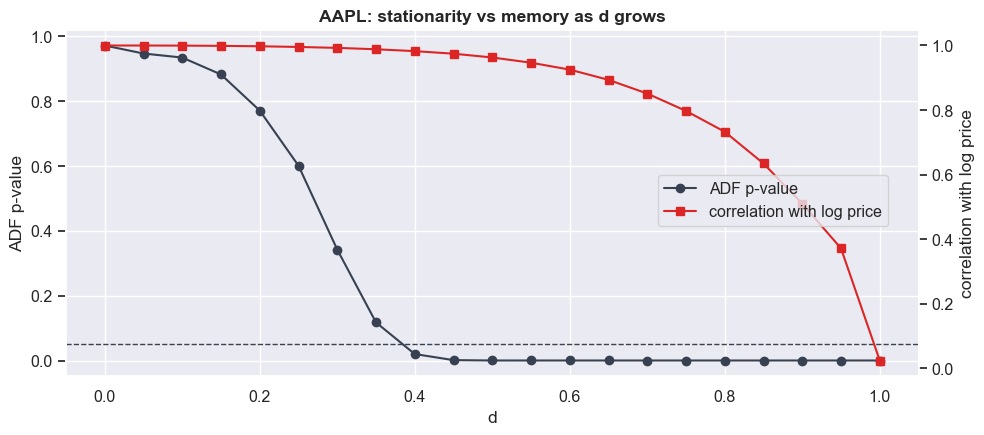

In [6]:
fig

**Answer:** 13 of the 14 stocks become stationary at $d$ between 0.30 and 0.45, far below $d = 1$, while the fractionally
differenced series keeps a 0.92–0.99 correlation with the original log price. `IBM` needs $d = 0$: its log price was already
stationary over the training years (it moved sideways). Returns ($d = 1$) would have thrown that memory away. Each stock uses its own minimal $d$
for the feature `ffd_close`.

# [3/8] Feature catalogue
All features at day $t$ use data up to and including $t$. $C$ = close, $r$ = daily log return.

| Group | Feature | Formula / meaning |
|---|---|---|
| Momentum | `ret_1`, `ret_5`, `ret_10`, `ret_21` | $\ln(C_t / C_{t-k})$ |
| Volatility | `vol_21` | std of $r$ over 21 days |
| | `vol_ratio_5_21` | short / long volatility (is volatility rising?) |
| | `atr_14` | Average True Range / $C_t$, with $TR = \max(H - L, |H - C_{t-1}|, |L - C_{t-1}|)$ |
| | `bb_width` | Bollinger band width $4\sigma_{20} / SMA_{20}$ |
| Oscillators | `rsi_14` | $1 - \frac{1}{1 + RS}$, $RS$ = average gain / average loss (Wilder, 14 days), scaled to [0, 1] |
| | `macd_hist` | $(EMA_{12} - EMA_{26}) - \text{signal}_9$, divided by $C_t$ |
| | `bb_pctb` | position inside the Bollinger bands: $\frac{C - (SMA_{20} - 2\sigma)}{4\sigma}$ |
| Trend | `dist_sma_50`, `dist_sma_200`, `dist_ema_21` | $C_t / MA - 1$ (from the SMA / EMA of my first version) |
| Volume | `volume_z` | z-score of log volume vs its 21-day mean |
| Memory | `ffd_close` | fractionally differenced log price (section 2) |
| Market | `mkt_ret_1`, `mkt_ret_5`, `mkt_vol_21` | the same for `SPY` |
| | `rel_strength_21` | stock 21-day return minus `SPY` 21-day return |
| | `beta_63` | $\frac{\text{Cov}(r, r_{SPY})}{\text{Var}(r_{SPY})}$ over 63 days |

# [4/8] Build features
> **Objective:** <u>compute</u> the features per stock and join them to the labels. The first ~200 days of each stock are dropped
> (the 200-day average needs a full window).

In [7]:
parts = []
for t in TICKERS:
    g = prices[prices.ticker == t].set_index("date")
    f = ticker_features(g, market, d_choice.loc[t, "min_d"])
    f["ticker"] = t
    parts.append(f.reset_index())
features = pd.concat(parts, ignore_index=True)
dataset = labels.merge(features, on=["date", "ticker"], how="inner").dropna(subset=FEATURES).reset_index(drop=True)

In [8]:
print(f"labelled events: {len(labels):,} -> with complete features: {len(dataset):,}")
dataset[FEATURES].describe().T[["mean", "std", "min", "max"]].round(3)

labelled events: 53,592 -> with complete features: 51,086


,mean,std,min,max
ret_1,0.001,0.025,-0.336,0.421
ret_5,0.004,0.056,-0.563,0.448
ret_10,0.008,0.077,-0.730,0.559
ret_21,0.018,0.113,-0.866,0.833
vol_21,0.022,0.012,0.003,0.117
vol_ratio_5_21,0.929,0.383,0.019,2.197
rsi_14,0.535,0.124,0.092,0.942
macd_hist,-0.000,0.008,-0.121,0.048
bb_pctb,0.560,0.324,-0.497,1.525
bb_width,0.153,0.104,0.014,1.100


# [5/8] Which features relate to the label?
> **Question:** do feature values differ between take-profit, time-out and stop-loss events (training period only)?
>
> **Kruskal-Wallis H test** (non-parametric one-way ANOVA on ranks), $H_0$: the three groups have the same distribution.
> **Effect size:** $\eta^2_H = \frac{H - k + 1}{n - k}$ with $k = 3$ groups — 0.01 small, 0.06 medium, 0.14 large.
> With tens of thousands of rows small effects are "significant", so the effect size matters most.

In [9]:
train_part = dataset[dataset.date < VALID_START]
rows = []
for f in FEATURES:
    groups = [train_part.loc[train_part.label == k, f] for k in CLASSES]
    h, p = stats.kruskal(*groups)
    rows.append({"feature": f, "H": h, "p_value": p, "eta2": (h - 3 + 1) / (len(train_part) - 3),
                 **{f"median_{CLASSES[k]}": g.median() for k, g in zip(CLASSES, groups)}})
kruskal = pd.DataFrame(rows).sort_values("eta2", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
s = kruskal.set_index("feature")["eta2"].sort_values()
ax.barh(s.index, s.values, color=PRICE_COLOR)
ax.set(title="Kruskal-Wallis effect size per feature (train)", xlabel="eta squared")
savefig(fig, "03_feature_effects")
plt.close(fig)

In [10]:
kruskal.round(4)

,feature,H,p_value,eta2,median_stop-loss,median_time-out,median_take-profit
4,vol_21,1269.1873,0.0000,0.0371,0.0155,0.0197,0.0159
9,bb_width,889.8523,0.0000,0.0260,0.1021,0.1285,0.1041
13,atr_14,376.6353,0.0000,0.0110,0.0226,0.0254,0.0232
17,mkt_ret_5,338.3034,0.0000,0.0098,0.0037,0.0066,0.0036
18,mkt_vol_21,254.4389,0.0000,0.0074,0.0068,0.0076,0.0069
1,ret_5,207.1310,0.0000,0.0060,0.0051,0.0102,0.0034
7,macd_hist,177.1151,0.0000,0.0051,-0.0001,0.0009,-0.0001
2,ret_10,170.6264,0.0000,0.0049,0.0096,0.0177,0.0082
16,mkt_ret_1,140.8336,0.0000,0.0041,0.0004,0.0013,0.0006
12,dist_ema_21,125.7093,0.0000,0.0036,0.0104,0.0148,0.0090


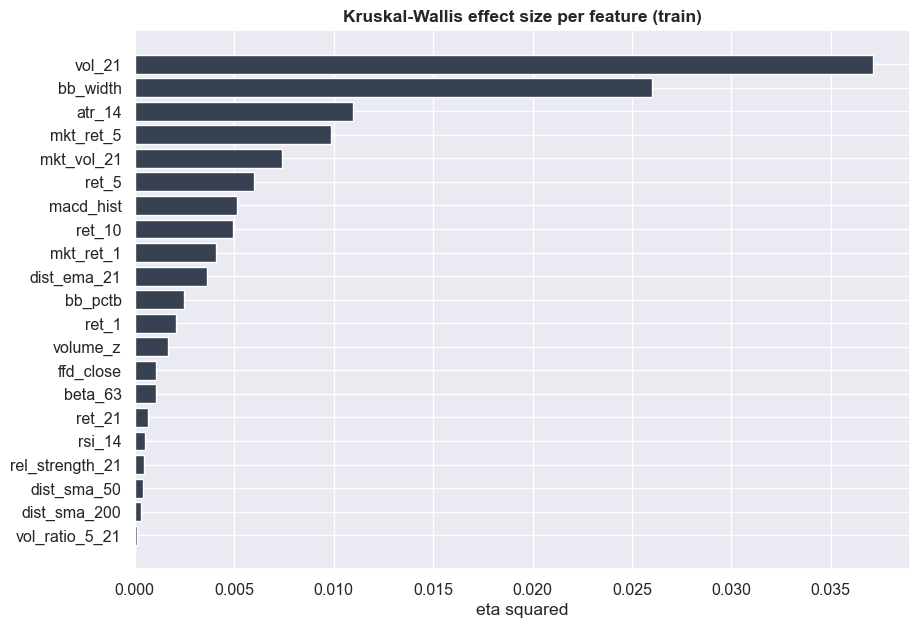

In [11]:
fig

**Answer:** every effect is **small** (largest $\eta^2$ = 0.037 for `vol_21`, then 0.026 for `bb_width` and 0.011 for `atr_14`):
the strongest features are related to **volatility** (they mainly separate time-outs from
barrier touches, because the barrier width is itself volatility-based), while momentum and oscillator features barely differ
between take-profit and stop-loss. This matches notebook 01: volatility is somewhat predictable, direction much less.
Expect modest model performance — the honest baseline for a hard problem.

# [6/8] Purged time split
> **Objective:** <u>split</u> by event start date — train < 2022, valid 2022–2023, test 2024 onwards — and **purge** events whose
> label end $t_1$ crosses into the next set.
>
> **Why purge?** An event starting on 2021-12-28 with $t_1$ = 2022-01-07 is labelled with January 2022 prices, which belong to the
> validation period. Keeping it in training leaks validation information into the model.

In [12]:
dataset["split"] = assign_split(dataset, VALID_START, TEST_START)
split_summary = dataset.groupby("split").agg(events=("label", "size"), start=("date", "min"), end=("date", "max"),
                                             take_profit=("label", lambda s: (s == 1).mean()),
                                             stop_loss=("label", lambda s: (s == -1).mean()),
                                             mean_uniqueness=("uniqueness", "mean"))
split_summary = split_summary.loc[["train", "purged", "valid", "test"]]

counts = dataset.groupby([dataset.date.dt.to_period("M"), "split"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(14, 3.8))
bottom = np.zeros(len(counts))
for s_name, c in SPLIT_COLORS.items():
    if s_name in counts:
        ax.bar(counts.index.to_timestamp(), counts[s_name], bottom=bottom, width=25, color=c, label=s_name)
        bottom += counts[s_name].to_numpy()
ax.set(title="Events per month by split", ylabel="events")
ax.legend(loc="upper left")
savefig(fig, "03_split")
plt.close(fig)

In [13]:
split_summary.round(3)

,events,start,end,take_profit,stop_loss,mean_uniqueness
split,,,,,,
train,34024,2010-10-18,2021-12-23,0.375,0.271,0.154
purged,244,2021-12-17,2023-12-29,0.119,0.619,0.132
valid,6892,2022-01-03,2023-12-22,0.349,0.335,0.157
test,9926,2024-01-02,2026-10-28,0.337,0.304,0.154


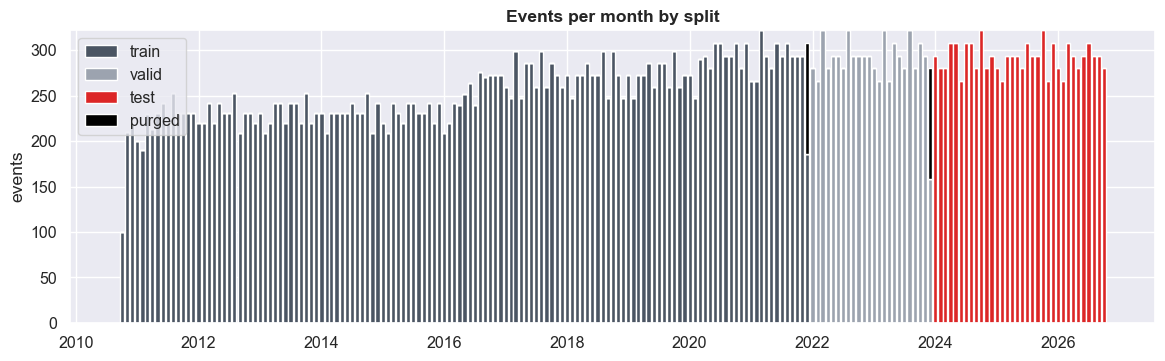

In [14]:
fig

**Answer:** 244 events are purged (about 9 per stock at each of the two boundaries; most are stop-losses that had not finished
when the period ended). Without purging they would let the model see the first days of the next period.
The class mix shifts between periods (take-profit 37.5 % in train vs 34–35 % later), another reason to judge models with macro-F1.

# [7/8] Save dataset
> Features are saved **unscaled**; scaling is fitted on the training split inside notebook 04.

In [15]:
keep = ["date", "ticker", "label", "t1", "ret", "barrier", "vol", "days_held", "uniqueness", "split"] + FEATURES
save_processed(dataset[keep], "dataset")
save_processed(d_choice.reset_index(), "frac_diff_d")

In [16]:
print(f"saved {len(dataset):,} rows x {len(keep)} columns")
dataset.split.value_counts()

saved 51,086 rows x 31 columns


split
train     34024
test       9926
valid      6892
purged      244
Name: count, dtype: int64

# [8/8] Summary
- **21 features**: momentum, volatility, oscillators, trend distance, volume, a fractionally differenced price and market context.
- Fractional differentiation makes prices stationary at $d$ = 0.30–0.45 (IBM: 0) while keeping memory that returns lose.
- Feature–label relationships are **weak** (all small effect sizes) — volatility features matter most.
- **Purged time split:** train < 2022, valid 2022–2023, test 2024 onwards.